# 00 · 同一辆小车，为什么需要不同的控制理论？

你要让一辆沿轨道移动的小车停在 **1 米处，而且停稳**。你能施加向前或向后的力，传感器首先只能报告位置。起初忽略限制，后来发现电机推力有限、速度不能太高，停靠点后方还有不能越过的边界。

这六篇笔记始终研究这辆车。每次加入一个现实问题，就引出一组新的数学工具。

**最终目标：** 从运动方程独立写出离散模型，解释 PID、LQR、观测器与 MPC 的联系，搭建约束 MPC，并用失败案例说明预测不等于保证。


[00 学习地图与小车建模](00_学习地图与小车建模.ipynb) · [01 经典控制与PID](01_经典控制与PID.ipynb) · [02 状态空间与LQR](02_状态空间与LQR.ipynb) · [03 观测器与Kalman滤波](03_观测器与Kalman滤波.ipynb) · [04 从有限时域优化到MPC](04_从有限时域优化到MPC.ipynb) · [05 综合实验与进阶路线](05_综合实验与进阶路线.ipynb)

每篇可独立运行；本篇内按顺序执行。图中英文标签对应正文中文术语，避免依赖本机中文字体。


## 1. 一条问题驱动的路线

| 篇章 | 小车遇到的问题 | 数学工具 | 运行后应能解释 |
|---|---|---|---|
| 00 建模 | 力怎样改变位置？ | 微分方程、矩阵、精确离散化 | 位置为什么不能瞬间改变 |
| 01 经典控制 | 根据当前位置误差推车，为什么会振荡？ | 传递函数、极点、频率响应、PID | P、I、D 分别补上什么 |
| 02 现代控制 | 位置相同但速度不同，该不该给同样的力？ | 状态空间、可控性、Lyapunov、LQR | 极点配置与最优反馈如何选增益 |
| 03 估计 | 只有带噪的位置，速度从哪里来？ | 可观性、Luenberger、Kalman、LQG、积分状态 | 为什么差分测速会放大噪声 |
| 04 MPC | 推力、速度和边界能否提前考虑？ | 有限时域、二次规划、滚动优化 | 为什么只执行计划的第一步 |
| 05 综合 | 噪声、扰动、质量变化一起出现会怎样？ | 公平比较、输出反馈、失配测试 | 哪些结论来自实验，哪些需要证明 |

建议安排：00–01 用 2 次学习，02–03 用 3 次，04 用 2 次，05 用 1–2 次；每次 60–90 分钟。先预测曲线形状，再运行；每次只改变一个参数。

### 先修知识，按使用顺序补

- **导数与积分：** 速度是位置的变化率，力经过质量转换为加速度；误差积分把过去误差积累起来。
- **线性代数：** 矩阵乘法、特征值、秩；第 02 篇用它们解释内部状态与稳定性。
- **概率：** 均值、方差、协方差；第 03 篇把预测与测量按可信度融合。
- **优化：** 二次函数最小值、约束；第 04 篇先算无约束解，再交给 QP 求解器。

不需要预先掌握凸优化或控制理论，但应能读懂 Python 函数与数组。


## 2. 从“经典”到“现代”，不是一条淘汰链

下面是重心变化的简化时间线，年代表示相关方法形成与发展的阶段，不表示唯一发明年份。

| 阶段 | 典型关注 | 在小车上怎样体现 |
|---|---|---|
| 早期反馈、1930–1950 年代经典控制 | 传递函数、频域、稳定裕度、PID | 看输入力到输出位置的响应，调整反馈 |
| 1950–1960 年代状态空间与最优控制 | 多变量内部动态、可控/可观、动态规划、LQR、Kalman | 同时考虑位置与速度，估计看不见的状态 |
| 1970–1980 年代工业预测控制的发展 | 利用模型预测、在线处理约束 | 预判刹车距离，而非越界后才纠偏 |
| 1980 年代以后鲁棒、自适应、非线性方法持续发展 | 模型不确定性、参数变化、非线性 | 质量变化、摩擦变化、复杂执行器 |
| 当代优化与学习控制 | 鲁棒/随机/非线性 MPC、数据驱动建模 | 更复杂模型与风险约束，关注实时求解与验证 |

**“现代控制理论”在课程中常特指状态空间体系；“当前先进控制”还包括 MPC 等更广的方向。** LQR 和 Kalman 已有数十年历史，今天仍是基础。PID 也仍常作为电机的快速内环，MPC 在较慢外环生成目标：这些方法可以协作。


## 3. 运行约定

在仓库根目录执行：

```bash
cd modern-control
uv sync --python 3.11.15
uv run jupyter lab
```

VS Code 选择本目录 `.venv/bin/python`。每篇重启内核后“运行全部”，无需前篇生成文件；安装后实验完全离线、只用 CPU。

NumPy/SciPy 负责矩阵、离散化和 Riccati 方程；Matplotlib 画图；CVXPY 将约束翻译成优化问题，OSQP 求解凸二次规划。显式使用优化建模库，是为了让 MPC 代码和数学约束逐行对应。锁文件记录本次验证版本。正文全部中文，图表标签和代码标识符用英文。

**读图约定：** 位置用米，速度用米/秒，力用牛顿，时间用秒。所有仿真以 0.1 秒采样，输入在采样间隔内保持不变。断言检查数学恒等式和关键实验结论，改参数后断言失败也是值得分析的结果。


## 4. 从牛顿第二定律开始

设位置 $p(t)$、速度 $v(t)$、控制推力 $u(t)$、未知外力 $d(t)$。质量 $m=1\,\mathrm{kg}$，线性阻力系数 $b_c=0.4\,\mathrm{N\,s/m}$：

$$\dot p=v,\qquad m\dot v=u-b_c v+d.$$

线性阻力刻画与速度成比例的阻力；真实小车的库仑摩擦、死区和电机延迟在后续工程建模时另加。

取状态、输入、输出：

$$x=\begin{bmatrix}p\\v\end{bmatrix},\quad
\dot x=A_c x+B_c(u+d),\quad y=Cx,$$
$$A_c=\begin{bmatrix}0&1\\0&-0.4\end{bmatrix},\quad
B_c=\begin{bmatrix}0\\1\end{bmatrix},\quad C=\begin{bmatrix}1&0\end{bmatrix}.$$

**状态是足以预测未来的信息。** 只知道 $p=0.9$ 不够：若 $v=+0.8$，可能需要刹车；若 $v=-0.8$，可能要往前拉。同一个位置可以对应完全不同的行动。

目标平衡点 $x_r=[1,0]^T$，无外力时 $u_r=0$；若恒定外力为 $d$，保持静止需要 $u_r=-d$。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, linalg

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
DT = 0.1
MASS, DRAG = 1.0, 0.4
C = np.array([[1.0, 0.0]])

def model(mass=MASS, drag=DRAG):
    Ac = np.array([[0.0, 1.0], [0.0, -drag / mass]])
    Bc = np.array([[0.0], [1.0 / mass]])
    A, B, _, _, _ = signal.cont2discrete((Ac, Bc, C, np.zeros((1, 1))), DT)
    return A, B

A, B = model()
b = B[:, 0]
REF = np.array([1.0, 0.0])

def rollout(policy, steps=120, x0=(0.0, 0.0), disturbance=None, plant=None):
    Ap, Bp = (A, B) if plant is None else plant
    xs, us = [np.array(x0, dtype=float)], []
    for k in range(steps):
        u = float(policy(xs[-1].copy(), k))
        d = 0.0 if disturbance is None else float(disturbance(k))
        xs.append(Ap @ xs[-1] + Bp[:, 0] * (u + d))
        us.append(u)
    return np.asarray(xs), np.asarray(us)

def plot_runs(runs, title, wall=None):
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    for label, (xs, us) in runs.items():
        axes[0].plot(np.arange(len(xs))*DT, xs[:, 0], label=label)
        axes[1].plot(np.arange(len(xs))*DT, xs[:, 1], label=label)
        axes[2].step(np.arange(len(us))*DT, us, where="post", label=label)
    axes[0].axhline(REF[0], color="black", ls=":", label="target")
    if wall is not None:
        axes[0].axhline(wall, color="firebrick", ls="--", label="position limit")
    for ax, label in zip(axes, ["position [m]", "velocity [m/s]", "force [N]"]):
        ax.set_ylabel(label)
    axes[0].legend(ncol=3, fontsize=8)
    axes[-1].set_xlabel("time [s]")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


## 5. 连续物理，离散决策

计算机每隔 $T_s=0.1\,\mathrm{s}$ 计算一次控制量。零阶保持（ZOH）假定这一小段内输入不变：

$$x_{k+1}=Ax_k+B(u_k+d_k),\qquad
A=e^{A_cT_s},\quad B=\int_0^{T_s}e^{A_c\tau}B_c\,d\tau.$$

不要直接套 $A_c^{-1}(A-I)B_c$：本例 $A_c$ 含积分器，不可逆。SciPy 的状态空间离散化能处理这种情况。

令 $\alpha=b_c/m$，可手工算出：

$$A=\begin{bmatrix}1&(1-e^{-\alpha T_s})/\alpha\\0&e^{-\alpha T_s}\end{bmatrix},\qquad
B=\begin{bmatrix}[T_s-(1-e^{-\alpha T_s})/\alpha]/b_c\\(1-e^{-\alpha T_s})/b_c\end{bmatrix}.$$

这里 $b_c>0$；当阻力趋于零时取极限 $B=[T_s^2/(2m),T_s/m]^T$。这也解释：力在一个采样周期内已经会改变位置，离散 $B$ 的第一项不为零。


A =
 [[1.     0.098 ]
 [0.     0.9608]] 
B =
 [[0.0049]
 [0.098 ]]
Discrete poles: [1.     0.9608]


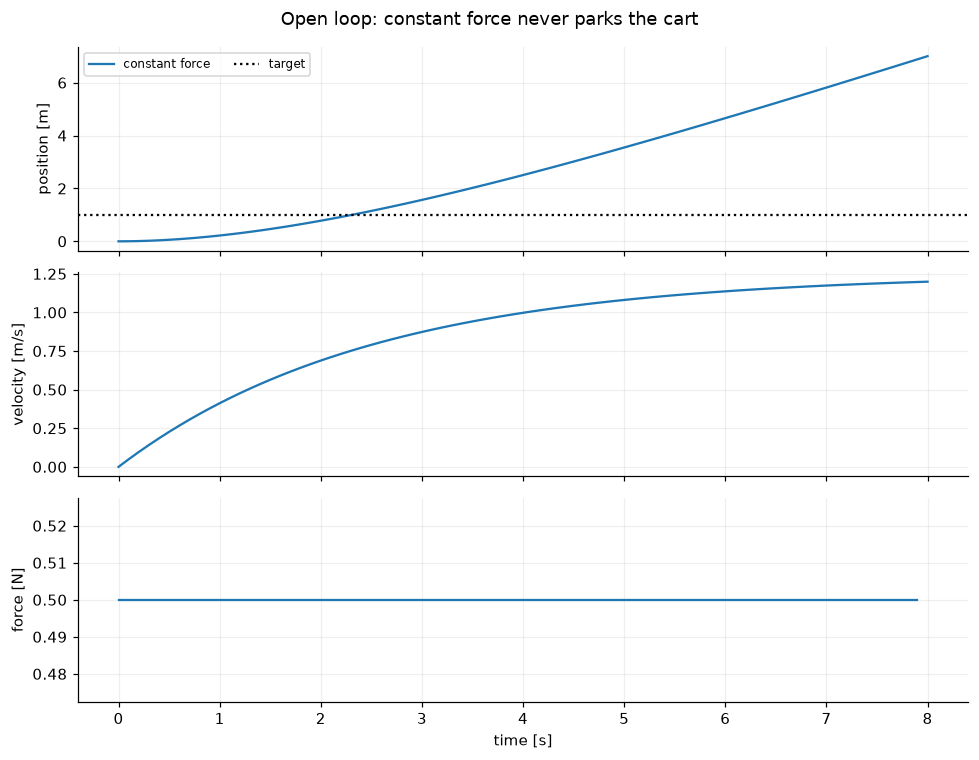

In [2]:
alpha = DRAG / MASS
q = np.exp(-alpha * DT)
A_exact = np.array([[1, (1-q)/alpha], [0, q]])
B_exact = np.array([[(DT-(1-q)/alpha)/DRAG], [(1-q)/DRAG]])
assert np.allclose(A, A_exact)
assert np.allclose(B, B_exact)
print("A =\n", A, "\nB =\n", B)
print("Discrete poles:", np.linalg.eigvals(A))

force = 0.5
xs, us = rollout(lambda x, k: force, steps=80)
t = np.arange(len(xs))*DT
p_exact = force/DRAG * (t - (1-np.exp(-alpha*t))/alpha)
v_exact = force/DRAG * (1-np.exp(-alpha*t))
assert np.max(np.abs(xs[:, 0]-p_exact)) < 1e-10
assert np.max(np.abs(xs[:, 1]-v_exact)) < 1e-10
plot_runs({"constant force": (xs, us)}, "Open loop: constant force never parks the cart")


### 读图：恒定推力为什么不能停靠？

阻力让速度趋向 $u/b_c=1.25\,\mathrm{m/s}$，却不能让位置停在 1 米。位置会继续增长。达到目标时切断力也不等于立刻停下：速度所代表的动量还在。

**开环控制**事先安排力；**闭环控制**不断测量结果、重新调整力。完整闭环是：目标 → 控制器 → 执行器 → 小车 → 传感器 → 控制器；未知外力进入小车，测量噪声进入传感器。

本例传递函数含原点极点，状态矩阵含离散特征值 1；没有反馈时位置不具备渐近回到目标的能力。


## 6. 统一实验协议

后文不会把不同假设混在一张“排行榜”里：

| 场景 | 初始状态 | 控制器能看到什么 | 限制与额外因素 |
|---|---|---|---|
| 理解反馈 | $[0,0]$ | 真实位置与速度 | 暂时不限制力，隔离反馈机制 |
| 估计实验 | $[0,0]$ | 只有带噪位置 | 随机种子固定，噪声方差明确 |
| 约束比较 | $[0,0]$ | 真实位置与速度 | $|u|\le1$，$|v|\le0.8$，$p\le1.05$ |
| 失配测试 | $[0,0]$ | 各控制器同样的状态信息 | 固定设计参数，改变真实质量/加入外力 |

默认运行 12 秒；约束检查先检查采样点。连续时间内是否越界需要额外的采样间检查或约束收紧，第 05 篇会明确区分。

### 贯穿全书的四个问题

1. **稳定吗？** 初始偏差会不会衰减？
2. **性能好吗？** 多久停稳，是否超调，输入代价多大？
3. **允许吗？** 执行器和安全边界是否满足？
4. **知道得准确吗？** 预测模型和状态估计有多可信？

稳定性、最优性、可行性、鲁棒性是不同命题。后面的理论和实验分别回答它们。


## 7. 自测与贯穿任务

先用纸回答，再看提示。

1. 小车已在 1 米处但速度是 $0.5\,\mathrm{m/s}$，算完成停靠吗？
2. 若外力恒为 $0.2\,\mathrm N$，平衡推力应是多少？
3. 把 `DT` 改为 0.5 时，是否需要重新计算 A、B 和控制器？
4. 将质量改成 2 kg，同样推力下最初加速度怎样变化？

<details><summary>检查思路</summary>

1. 没有，目标包含速度为零。2. $-0.2\,\mathrm N$。3. 需要，采样模型与离散控制增益都随采样周期变化。4. 静止时阻力为零，加速度减半；之后整条响应也会变化。

</details>

**下一篇的问题：** 既然位置误差越大就推得越用力很自然，为什么这种方法仍会冲过目标？
